# Day 71: PCA — Dimensionality Reduction Intuition

## Objective
- See why too many features can hurt (curse of dimensionality)
- Understand PCA as "finding the best new axes"
- Build PCA by hand with NumPy (no magic)
- Know when PCA helps: visualization, multicollinearity, speed

> **Data note:** `dataset.csv` is made-up. 400 football players, 6 rating columns that are driven by
> two hidden skills (athleticism and technique), plus a `starter` label.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

## Theory
- **Curse of dimensionality:** as features grow, data gets spread thin and distances stop being useful
  - every point looks about equally far from every other point
  - distance-based models (KNN, K-Means) suffer first
- **PCA (Principal Component Analysis):** finds new axes that capture the **most variance** in fewer dimensions
- **Principal component:** a new axis made by mixing the original features (a **linear combination**)
- PC1 captures the most variance, PC2 the next most, and so on
- Principal components are **uncorrelated** with each other by construction
- Scale first, because PCA is driven by variance

In [2]:
df = pd.read_csv("dataset.csv")
features = ["sprint_speed", "acceleration", "stamina", "dribbling", "passing", "ball_control"]
X_scaled = StandardScaler().fit_transform(df[features])
y = df["starter"]
print(df.shape)

(400, 8)


## Example 1: The curse of dimensionality

In [3]:
# Random points: how different are the nearest and farthest neighbours?
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000]:
    points = rng.random((500, d))
    dists = np.linalg.norm(points[1:] - points[0], axis=1)
    ratio = (dists.max() - dists.min()) / dists.min()
    print("dimensions", d, "-> (farthest - nearest) / nearest =", round(ratio, 2))

dimensions 2 -> (farthest - nearest) / nearest = 66.13
dimensions 10 -> (farthest - nearest) / nearest = 2.32
dimensions 100 -> (farthest - nearest) / nearest = 0.36
dimensions 1000 -> (farthest - nearest) / nearest = 0.11


In [4]:
# KNN with 2 useful features + more and more useless noise columns
base = df[["sprint_speed", "dribbling"]].to_numpy()
base = StandardScaler().fit_transform(base)

for n_noise in [0, 10, 50, 200]:
    noise = np.random.default_rng(1).normal(size=(len(df), n_noise))
    X_try = np.hstack([base, noise])
    Xtr, Xte, ytr, yte = train_test_split(X_try, y, test_size=0.25, random_state=42, stratify=y)
    knn = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
    print(n_noise, "noise columns -> accuracy", round(accuracy_score(yte, knn.predict(Xte)), 3))

0 noise columns -> accuracy 0.77
10 noise columns -> accuracy 0.69
50 noise columns -> accuracy 0.51
200 noise columns -> accuracy 0.65


## Example 2: Correlated features hide the real story

In [5]:
# Six columns, but they move in two groups
print(pd.DataFrame(X_scaled, columns=features).corr().round(2))

              sprint_speed  acceleration  stamina  dribbling  passing  \
sprint_speed          1.00          0.85     0.77       0.39     0.35   
acceleration          0.85          1.00     0.78       0.35     0.32   
stamina               0.77          0.78     1.00       0.30     0.28   
dribbling             0.39          0.35     0.30       1.00     0.83   
passing               0.35          0.32     0.28       0.83     1.00   
ball_control          0.38          0.35     0.30       0.87     0.83   

              ball_control  
sprint_speed          0.38  
acceleration          0.35  
stamina               0.30  
dribbling             0.87  
passing               0.83  
ball_control          1.00  


## Example 3: PCA by hand

In [6]:
# Step 1: covariance matrix (how features vary together)
cov = np.cov(X_scaled.T)

# Step 2: eigenvectors = new axes, eigenvalues = variance on each axis
eigvals, eigvecs = np.linalg.eigh(cov)

# Step 3: sort from biggest variance to smallest
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

share = eigvals / eigvals.sum()
for i, s in enumerate(share, start=1):
    print("PC" + str(i), "captures", round(s * 100, 1), "% of the variance")

PC1 captures 61.0 % of the variance
PC2 captures 27.2 % of the variance
PC3 captures 4.2 % of the variance
PC4 captures 3.0 % of the variance
PC5 captures 2.5 % of the variance
PC6 captures 2.1 % of the variance


## Example 4: Principal components are linear combinations

In [7]:
# Each PC is just a weighted mix of the 6 original features
loadings = pd.DataFrame(eigvecs[:, :2], index=features, columns=["PC1", "PC2"])
print(loadings.round(2))

               PC1   PC2
sprint_speed -0.41 -0.39
acceleration -0.40 -0.42
stamina      -0.38 -0.44
dribbling    -0.42  0.39
passing      -0.41  0.41
ball_control -0.42  0.39


## Example 5: Principal components are uncorrelated

In [8]:
# Project the data onto the new axes
scores = X_scaled @ eigvecs

# Correlation between PCs: everything off the diagonal should be ~0
pc_corr = np.corrcoef(scores.T)
off_diag = pc_corr[~np.eye(6, dtype=bool)]
print("Biggest |correlation| between two PCs:", round(np.abs(off_diag).max(), 6))

orig_corr = np.corrcoef(X_scaled.T)
orig_off = orig_corr[~np.eye(6, dtype=bool)]
print("Biggest |correlation| between two original features:", round(np.abs(orig_off).max(), 2))

Biggest |correlation| between two PCs: 0.0
Biggest |correlation| between two original features: 0.87


## Example 6: Check against sklearn (more on this tomorrow)

In [9]:
pca = PCA(n_components=2)
pca.fit(X_scaled)
print("sklearn:", (pca.explained_variance_ratio_ * 100).round(1))
print("by hand:", (share[:2] * 100).round(1))

sklearn: [61.  27.2]
by hand: [61.  27.2]


## Example 7: Visualize 6 features in 2D

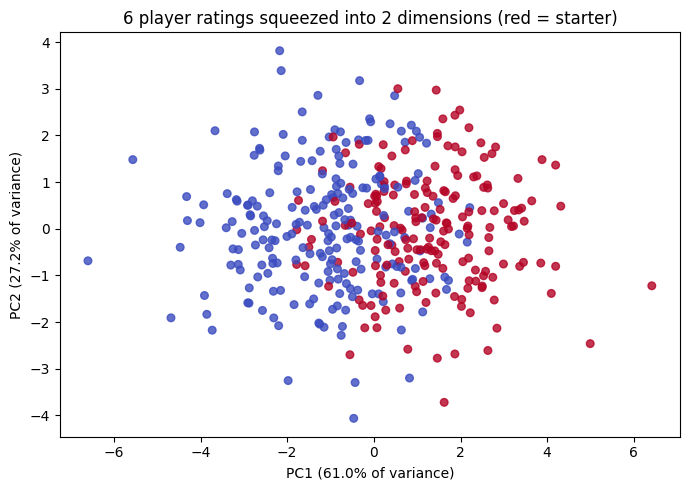

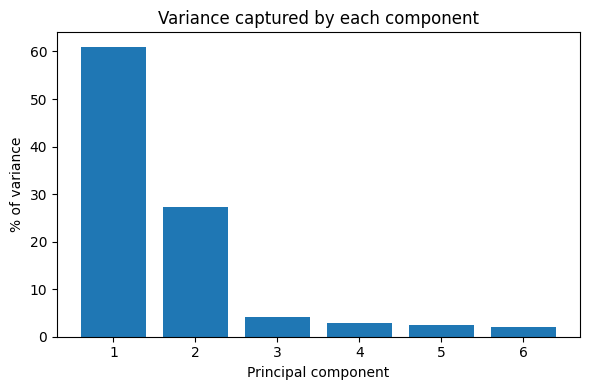

In [10]:
pc2 = pca.transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(pc2[:, 0], pc2[:, 1], c=y, cmap="coolwarm", s=30, alpha=0.8)
plt.xlabel("PC1 (" + str(round(share[0] * 100, 1)) + "% of variance)")
plt.ylabel("PC2 (" + str(round(share[1] * 100, 1)) + "% of variance)")
plt.title("6 player ratings squeezed into 2 dimensions (red = starter)")
plt.tight_layout()
plt.savefig("images/pca_2d_scatter.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(range(1, 7), share * 100, color="#1f77b4")
plt.xlabel("Principal component")
plt.ylabel("% of variance")
plt.title("Variance captured by each component")
plt.tight_layout()
plt.savefig("images/variance_per_component.png", dpi=150)
plt.show()

## Example 8: Does squeezing hurt a model?

In [11]:
Xtr, Xte, ytr, yte = train_test_split(X_scaled, y, test_size=0.25, random_state=42, stratify=y)
knn_all = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
print("KNN, all 6 features:", round(accuracy_score(yte, knn_all.predict(Xte)), 3))

# Fit PCA on training data only, then transform both parts
pca2 = PCA(n_components=2).fit(Xtr)
knn_pca = KNeighborsClassifier(n_neighbors=5).fit(pca2.transform(Xtr), ytr)
print("KNN, 2 PCA features:", round(accuracy_score(yte, knn_pca.predict(pca2.transform(Xte))), 3))

KNN, all 6 features: 0.78
KNN, 2 PCA features: 0.8


## Practice Exercise
Using `share`, how many principal components do you need to capture at least 80% of the variance?

In [12]:
# Your turn: cumulative variance
cumulative = np.cumsum(share)
print((cumulative * 100).round(1))
print("Components needed for 80%:", int(np.argmax(cumulative >= 0.80)) + 1)

[ 61.   88.2  92.4  95.4  97.9 100. ]
Components needed for 80%: 2


## Mini Challenge
Which original feature has the biggest absolute weight on PC1? Which has the biggest on PC2?

In [13]:
print("Biggest on PC1:", loadings["PC1"].abs().idxmax())
print("Biggest on PC2:", loadings["PC2"].abs().idxmax())

Biggest on PC1: ball_control
Biggest on PC2: stamina


## Summary
- More features can hurt, especially for distance-based models
- PCA finds new axes (mixes of old features) that hold the most variance
- Components are uncorrelated, so PCA removes multicollinearity
- 6 correlated ratings became 2 useful dimensions
- Always scale first, and fit PCA on training data only when you build a model